# ReMedFiLM — Complete Research Master

**Proposed system:** ReMedFiLM = FULL RA-MedFiLM-BARR
**Composition:** G (GlobalMedFiLM) + B_phi (Benefit Router) + R_psi (Regional Refiner)
+ S_omega (Post-Safety Gate)
**Parameters:** 4,837,420 · **VAL808 macro Dice:** 0.837290 (seed 42)

This notebook is the single entry point to the project. It is organised around the
**FULL ReMedFiLM workflow**, not chronological phase numbers. Every number traces to
a frozen artifact; every figure is generated from saved evidence.

| | |
|---|---|
| Execution mode | `ANALYSIS_ONLY` — training, inference and TEST access are blocked |
| Analysis seed | 20261027 |
| Population discipline | TRAIN 5,832 · VAL 808 · ROUTER_DEV 4,957 · ROUTER_HOLDOUT 875 · TEST 1,683 (consumed) |

> GlobalMedFiLM alone is **not** ReMedFiLM. It is the backbone and an ablation comparator.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


---

# 01 — Research overview

Why the architecture is global-to-regional, and why the assembly matters.

In [3]:
print("The problem")
print("-----------")
print("Medical segmentation models trained per-domain are expensive; one shared")
print("model across ISIC/BUSI/KVASIR/KUB must handle very different lesion scales.")
print("KUB stones can be a few hundred pixels inside a 512x512 field, while ISIC")
print("lesions can occupy most of the frame.")
print()
print("The idea")
print("--------")
print("Let one task-conditioned global model do the easy 80% cheaply, and spend")
print("extra compute only where a learned router predicts a real benefit - with a")
print("safety gate that can veto a bad refinement.")

The problem
-----------
Medical segmentation models trained per-domain are expensive; one shared
model across ISIC/BUSI/KVASIR/KUB must handle very different lesion scales.
KUB stones can be a few hundred pixels inside a 512x512 field, while ISIC
lesions can occupy most of the frame.

The idea
--------
Let one task-conditioned global model do the easy 80% cheaply, and spend
extra compute only where a learned router predicts a real benefit - with a
safety gate that can veto a bad refinement.


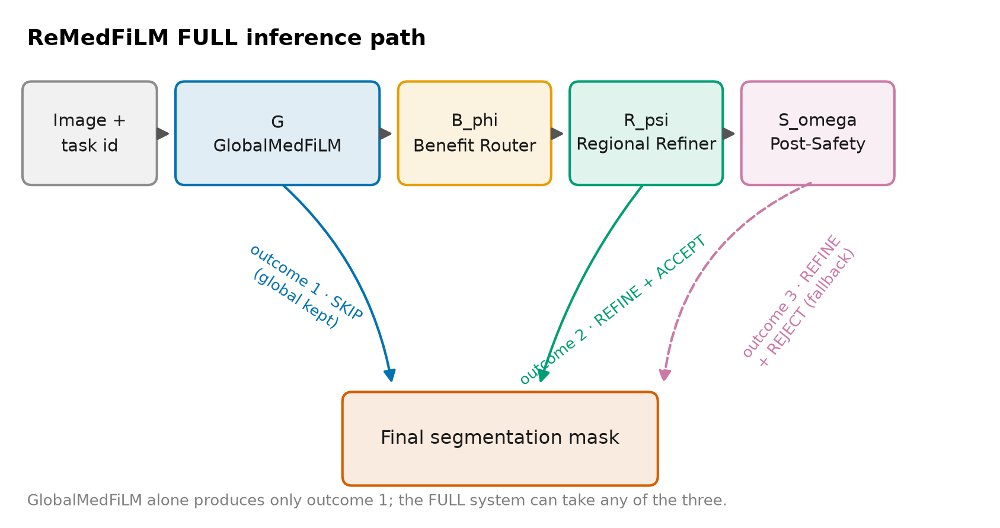

In [4]:
fig("Architecture", "A03_remedfilm_inference_path", width=800)

In [5]:
print("Four domains, four binary tasks")
print("-------------------------------")
for d, note in [("ISIC 2018", "dermoscopy, CC0"),
                ("BUSI-WHU", "breast ultrasound, CC BY 4.0"),
                ("Kvasir-SEG", "GI polyp, research use"),
                ("KUB-StoneX", "stone radiograph, CC BY 4.0")]:
    print(f"  {d:14s} {note}")
print()
print("These are separate binary foreground/background tasks, not four output")
print("channels of one network.")

Four domains, four binary tasks
-------------------------------
  ISIC 2018      dermoscopy, CC0
  BUSI-WHU       breast ultrasound, CC BY 4.0
  Kvasir-SEG     GI polyp, research use
  KUB-StoneX     stone radiograph, CC BY 4.0

These are separate binary foreground/background tasks, not four output
channels of one network.


---

# 02 — ReMedFiLM architecture

Exact components, parameters and inference outcomes, read from the frozen contract.

In [6]:
parts = pd.read_csv(TABLES / "REMEDFILM_COMPONENT_PARAMETERS.csv")
parts[["symbol", "model_class", "role", "conditional", "parameters"]].to_string(index=False)

' symbol           model_class             role  conditional  parameters\n      G         GlobalMedFiLM GLOBAL_SEGMENTER        False     3523001\n  R_psi BARRRegionalRefinerV1 REGIONAL_REFINER         True     1276401\n  B_phi   BARRBenefitRouterV1   BENEFIT_ROUTER         True       36801\nS_omega      BARRPostSafetyV1      POST_SAFETY         True        1217\n   FULL             assembled  PROPOSED_SYSTEM         True     4837420'

In [7]:
comp = parts[parts.symbol != "FULL"].set_index("symbol").parameters.astype(int)
total = int(parts[parts.symbol == "FULL"].parameters.iloc[0])
print("component sum:", int(comp.sum()), "| contract total:", total)
assert int(comp.sum()) == total, "component arithmetic does not close"
print("OK — arithmetic closes")
print()
print("DATA DEFECT DISCLOSURE")
print("----------------------")
raw = pd.read_csv(REPO / "reports/tables/phase26_component_inventory.csv")
print("phase26_component_inventory.csv stores G.parameters =",
      int(raw[raw.symbol == "G"].parameters.iloc[0]))
print("That value is G's total MACs, not its parameter count. The frozen table is")
print("left unmodified; this notebook uses the corrected derived table above.")
print("Recorded as DEFECT-01 in SCIENTIFIC_CORRECTIONS.json.")

component sum: 4837420 | contract total: 4837420
OK — arithmetic closes

DATA DEFECT DISCLOSURE
----------------------
phase26_component_inventory.csv stores G.parameters = 31551740928
That value is G's total MACs, not its parameter count. The frozen table is
left unmodified; this notebook uses the corrected derived table above.
Recorded as DEFECT-01 in SCIENTIFIC_CORRECTIONS.json.


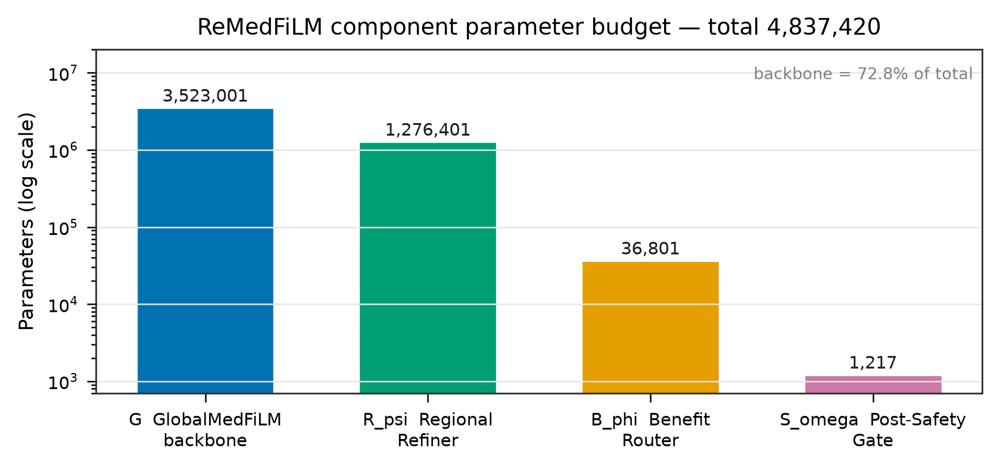

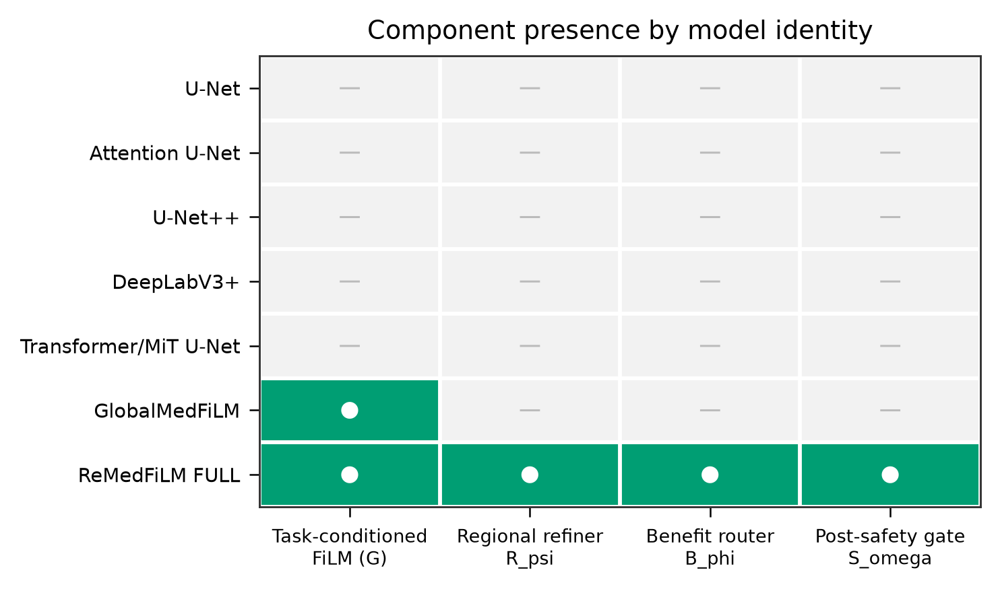

In [8]:
fig("Architecture", "A01_component_parameter_budget", width=720)
fig("Architecture", "A02_component_presence_matrix", width=520)

In [9]:
b = json.loads((REPO / "reports/audits/phase21_global_medfilm_architecture_binding.json").read_text(encoding="utf-8"))
for k in ("architecture_id", "film_sites", "film_equation", "task_embedding_dim", "heads"):
    if k in b:
        print(f"{k}: {b[k]}")

architecture_id: global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1


In [10]:
print("ASSEMBLY — not joint training")
print("-----------------------------")
print("G, R_psi, B_phi and S_omega were fitted separately and sequentially, each")
print("against a frozen upstream. No optimiser ever saw all four at once.")
print("Every ReMedFiLM claim is a claim about this assembly.")

ASSEMBLY — not joint training
-----------------------------
G, R_psi, B_phi and S_omega were fitted separately and sequentially, each
against a frozen upstream. No optimiser ever saw all four at once.
Every ReMedFiLM claim is a claim about this assembly.


---

# 03 — Dataset protocol

What was trained on what, and the grouping limitations that follow.

In [11]:
comp = pd.read_csv(TABLES / "REMEDFILM_DATASET_COMPOSITION.csv")
comp

,domain,train,val,total
0,ISIC,2556,357,2913
1,BUSI,602,84,686
2,KVASIR,696,87,783
3,KUB,1978,280,2258
4,TOTAL,5832,808,6640


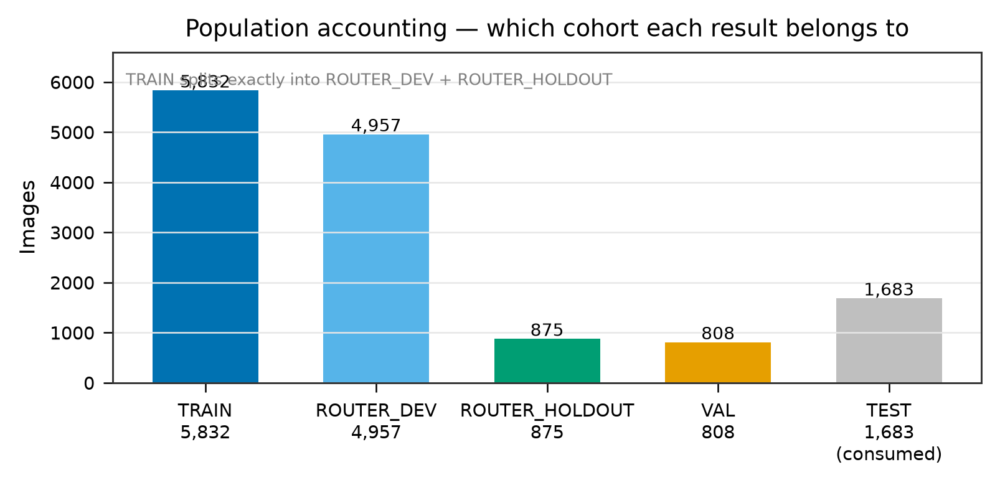

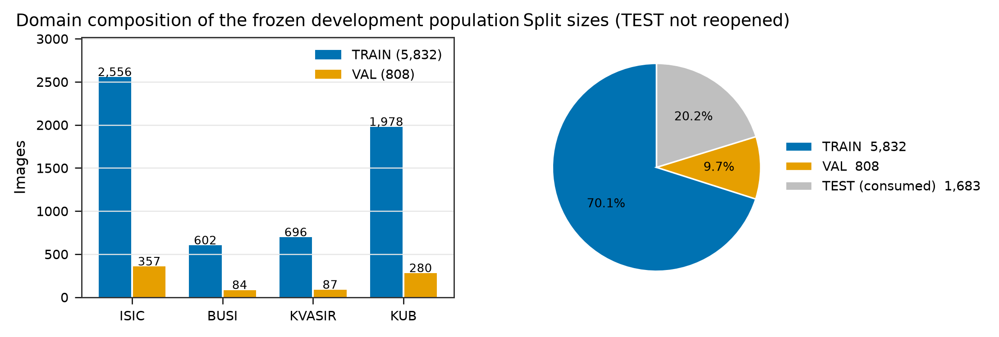

In [12]:
fig("Statistics", "STAT04_population_accounting", width=660)
fig("Statistics", "D01_domain_and_split_composition", width=780)

In [13]:
print("Grouping limitations (disclosed, not corrected)")
print("-----------------------------------------------")
print("1. KUB mixes full-field radiographs with ROI instance patches:")
print("   2,258 manifest rows = 873 full images + 1,385 ROI patches.")
print("2. BUSI and KUB carry patient identifiers; images from one patient are")
print("   not independent, so image-level bootstrap CIs are optimistic.")
print("3. VAL808 draws ISIC images from three pooled source archives, which were")
print("   re-split; VAL/TEST sample overlap is zero.")

Grouping limitations (disclosed, not corrected)
-----------------------------------------------
1. KUB mixes full-field radiographs with ROI instance patches:
   2,258 manifest rows = 873 full images + 1,385 ROI patches.
2. BUSI and KUB carry patient identifiers; images from one patient are
   not independent, so image-level bootstrap CIs are optimistic.
3. VAL808 draws ISIC images from three pooled source archives, which were
   re-split; VAL/TEST sample overlap is zero.


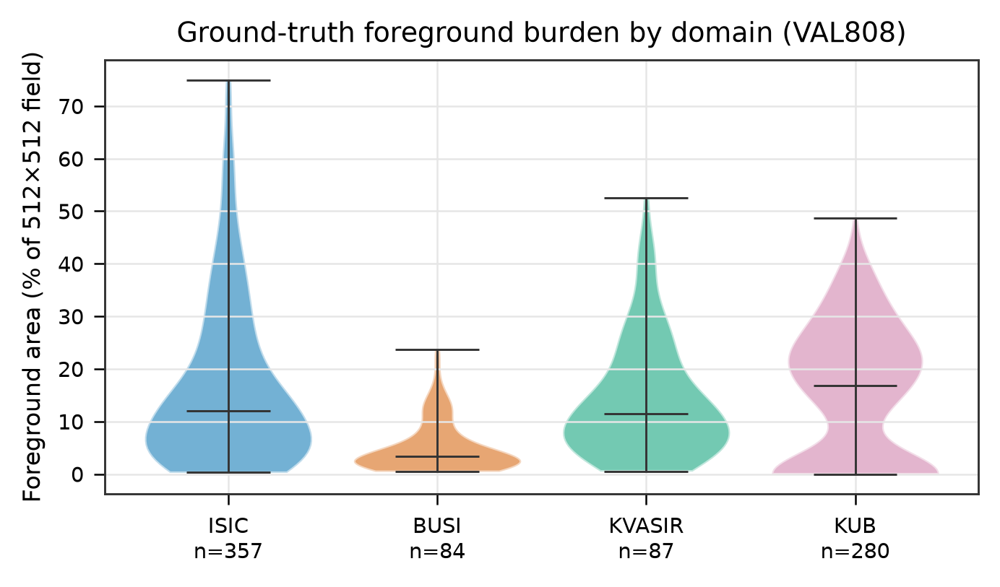

In [14]:
fig("Statistics", "D02_foreground_area_distribution", width=600)

---

# 04 — Historical component training

What was actually trained, with which recipe, and in what order.

In [15]:
cl = json.loads((REPO / "experiments/phase21_global_medfilm_fourdomain_seed42_clean_v3/closure.json").read_text(encoding="utf-8"))
cfg = cl["configuration"]
print("G — GlobalMedFiLM backbone")
print("  population :", cfg["dataset"])
print("  epochs     :", cl["total_completed_epochs"], "| best", cl["best_epoch"],
      "| stop", cl["stop_reason"])
print("  optimizer  :", cfg["optimizer"]["name"], cfg["optimizer"]["learning_rate"])
print("  scheduler  :", cfg["scheduler"]["name"], cfg["scheduler"]["T_max"])
print("  loss       :", cfg["loss"]["name"], cfg["loss"]["bce_weight"], "/", cfg["loss"]["dice_weight"])
print("  batch      :", cfg["training"]["batch_size"], "| amp", cfg["training"]["amp"])
print("  selection  :", cfg["training"]["checkpoint_metric"])
print("  best ckpt  :", cl["best_checkpoint_sha256"][:32], "...")
print("  wall clock :", round(cl["total_elapsed_seconds"] / 3600, 2), "h")

G — GlobalMedFiLM backbone
  population : MULTI_DOMAIN_ISIC_BUSI_KVASIR_KUB
  epochs     : 81 | best 66 | stop EARLY_STOPPING_PATIENCE
  optimizer  : AdamW 0.0001
  scheduler  : CosineAnnealingLR 100
  loss       : bce_dice 0.5 / 0.5
  batch      : 4 | amp True
  selection  : phase20_macro_domain_mean_dice_v1
  best ckpt  : 286689fdd5c63ad75a383151d267af8b ...
  wall clock : 9.61 h


In [16]:
reg = pd.read_csv(TABLES / "TRAINING_RUN_REGISTRY.csv")
print("total runs:", len(reg))
print(reg.groupby("model_role").size().to_string())
print()
print("evidence status:")
print(reg.evidence_status.value_counts().to_string())

total runs: 82
model_role
ABLATION       3
BASELINE      13
COMPONENT     52
G_BACKBONE     1
PRECURSOR     13

evidence status:
evidence_status
GENUINE_HISTORICAL_TRAINING              68
GENUINE_HISTORY_BEST_EPOCH_UNRESOLVED    14


In [17]:
comp = reg[reg.model_role.isin(["BACKBONE", "COMPONENT"])]
comp[["run_id", "model", "seed", "epochs_completed", "best_epoch",
      "best_epoch_source", "evidence_status"]].head(20)

,run_id,model,seed,epochs_completed,best_epoch,best_epoch_source,evidence_status
22,phase25a_barr_regional_refiner_v1_1__final_refit,R_psi (Regional Refiner),42,27,NOT_APPLICABLE,NOT_APPLICABLE_FIXED_EPOCH_REFIT,GENUINE_HISTORICAL_TRAINING
23,phase25a_barr_regional_refiner_v1_1__fold0,R_psi (Regional Refiner),42,50,34,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
24,phase25a_barr_regional_refiner_v1_1__fold1,R_psi (Regional Refiner),42,43,27,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
25,phase25a_barr_regional_refiner_v1_1__fold2,R_psi (Regional Refiner),42,34,18,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
26,phase25a_barr_regional_refiner_v1_1_roi030__fi...,R_psi (Regional Refiner),42,25,NOT_APPLICABLE,NOT_APPLICABLE_FIXED_EPOCH_REFIT,GENUINE_HISTORICAL_TRAINING
27,phase25a_barr_regional_refiner_v1_1_roi030__fold0,R_psi (Regional Refiner),42,41,25,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
28,phase25a_barr_regional_refiner_v1_1_roi030__fold1,R_psi (Regional Refiner),42,36,20,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
29,phase25a_barr_regional_refiner_v1_1_roi030__fold2,R_psi (Regional Refiner),42,41,25,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
30,phase25d_barr_benefit_router_v1_2_1_seed42__final,B_phi (Benefit Router),42,80,NOT_RECORDED,NOT_RECORDED,GENUINE_HISTORY_BEST_EPOCH_UNRESOLVED
31,phase25d_barr_benefit_router_v1_2_1_seed42__fold0,R_psi (Regional Refiner),42,57,37,RECORDED_FLAG,GENUINE_HISTORICAL_TRAINING


In [18]:
print("DEPENDENCY CHAIN")
print("----------------")
print("G   (21)   TRAIN5832 -> VAL808 selection")
print(" +-> R_psi (25A)  ROI crops, 3 cross-fitted folds + final refit")
print("      +-> B_phi (25D)  OOF gain labels, 5 CV folds + final")
print("           +-> S_omega (25F)  routed candidates, 5 CV folds + final")
print("                +-> assembly (26) -> eval (27/29/30)")

DEPENDENCY CHAIN
----------------
G   (21)   TRAIN5832 -> VAL808 selection
 +-> R_psi (25A)  ROI crops, 3 cross-fitted folds + final refit
      +-> B_phi (25D)  OOF gain labels, 5 CV folds + final
           +-> S_omega (25F)  routed candidates, 5 CV folds + final
                +-> assembly (26) -> eval (27/29/30)


---

# 05 — Epoch-wise training evidence

Genuine per-epoch records only. Nothing interpolated.

In [19]:
hist = pd.read_csv(TABLES / "REMEDFILM_EPOCH_HISTORY.csv")
print("records:", len(hist), "| runs:", hist.run_id.nunique(),
      "| metrics:", hist.metric.nunique())
hist.head(6)

records:

 35764 | runs: 82 | metrics: 42


,run_id,model_identity,model_role,seed,epoch,metric,value,source_metric_column,source_path
0,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,train_loss,1.245044e+01,train_loss,experiments/h3_kub_localizer_sigma_adaptive_si...
1,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,val_loss,1.037506e+01,val_loss,experiments/h3_kub_localizer_sigma_adaptive_si...
2,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,learning_rate,9.997533e-05,learning_rate,experiments/h3_kub_localizer_sigma_adaptive_si...
3,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,epoch_seconds,3.292958e+02,epoch_seconds,experiments/h3_kub_localizer_sigma_adaptive_si...
4,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,peak_gpu_allocated,7.555871e+08,peak_gpu_allocated,experiments/h3_kub_localizer_sigma_adaptive_si...
5,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,peak_gpu_reserved,9.059697e+08,peak_gpu_reserved,experiments/h3_kub_localizer_sigma_adaptive_si...


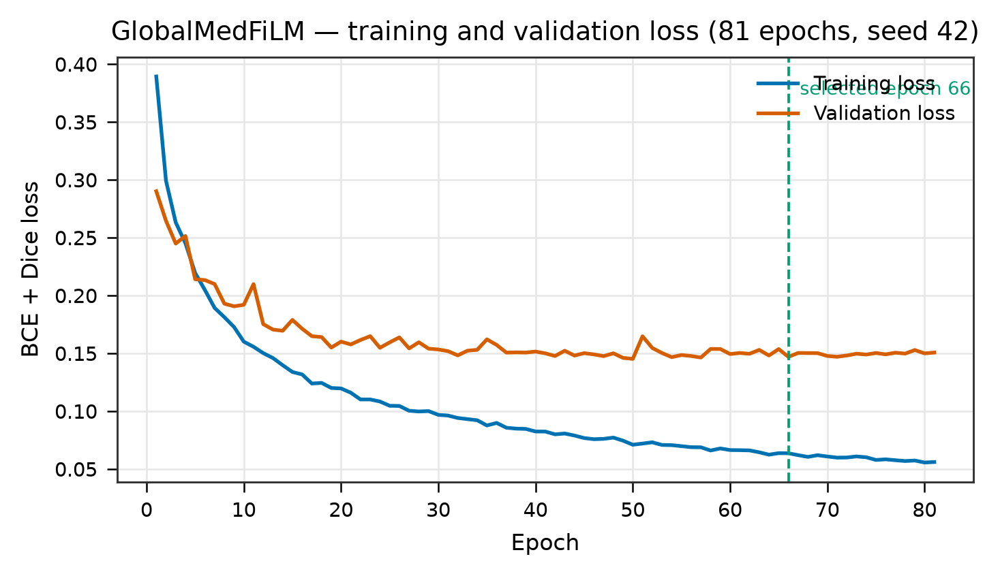

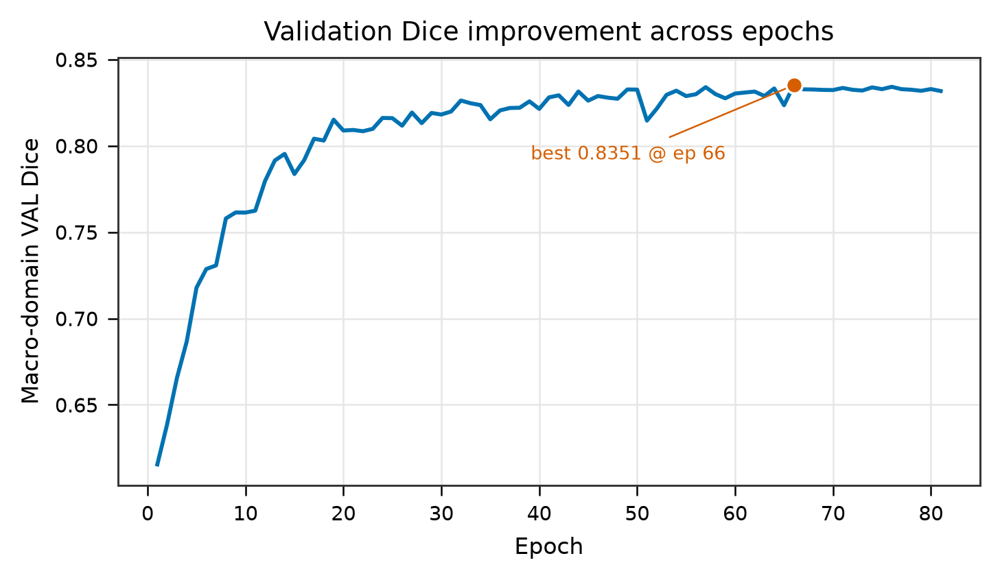

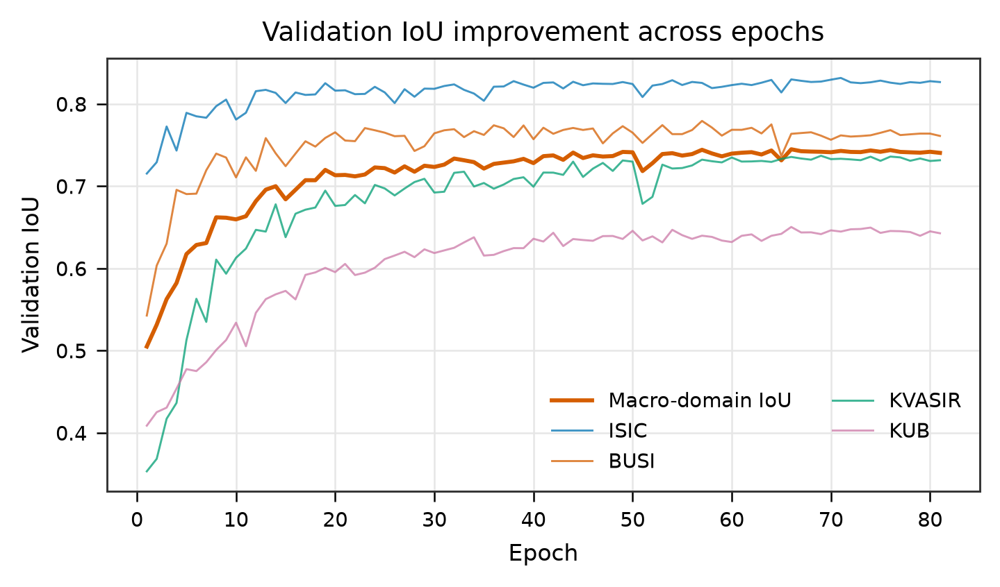

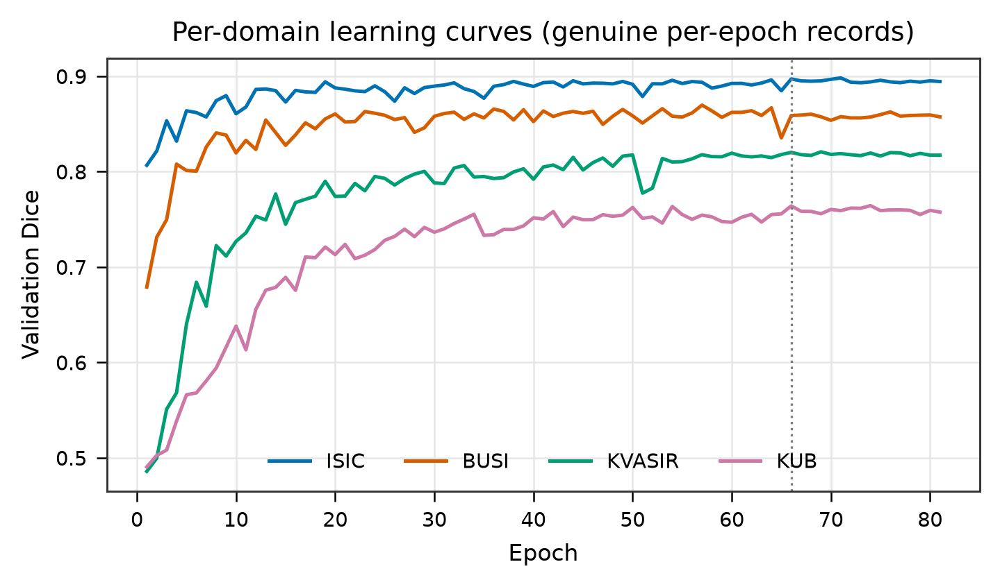

In [20]:
for name in ["T1_train_val_loss", "T2_val_dice_across_epochs",
             "T3_val_iou_across_epochs", "T4_per_domain_learning_curves"]:
    fig("Training curves", name, width=700)

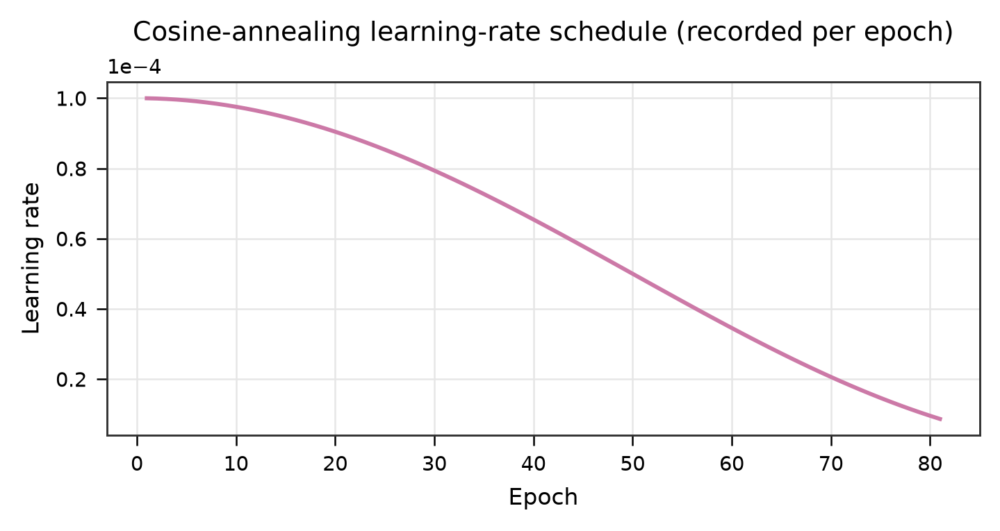

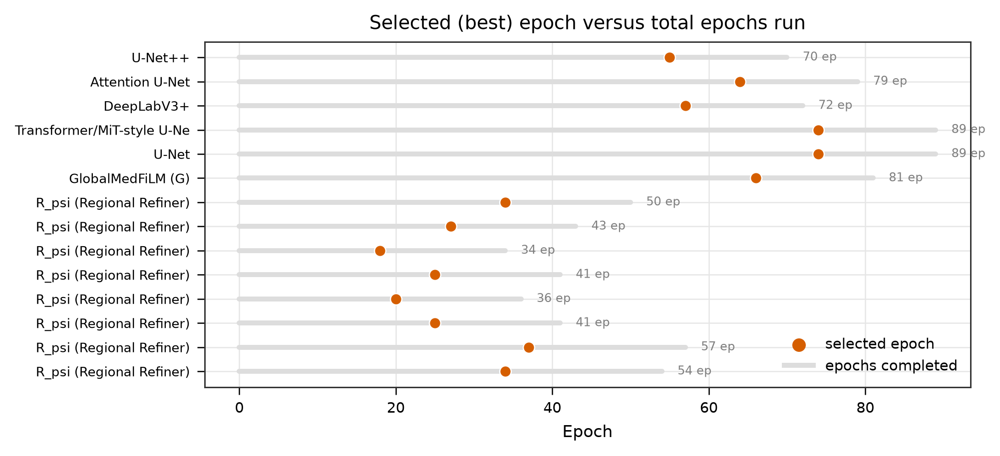

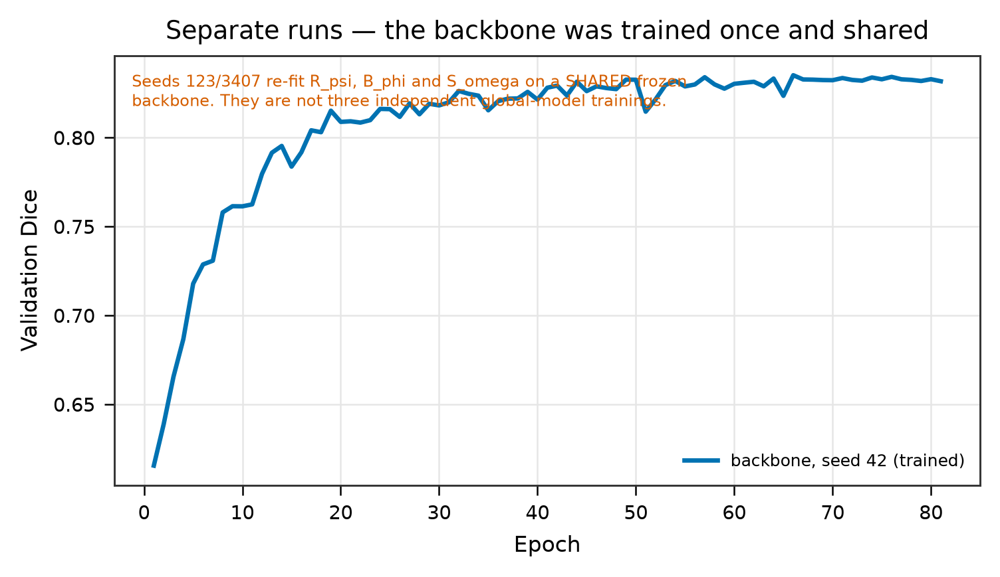

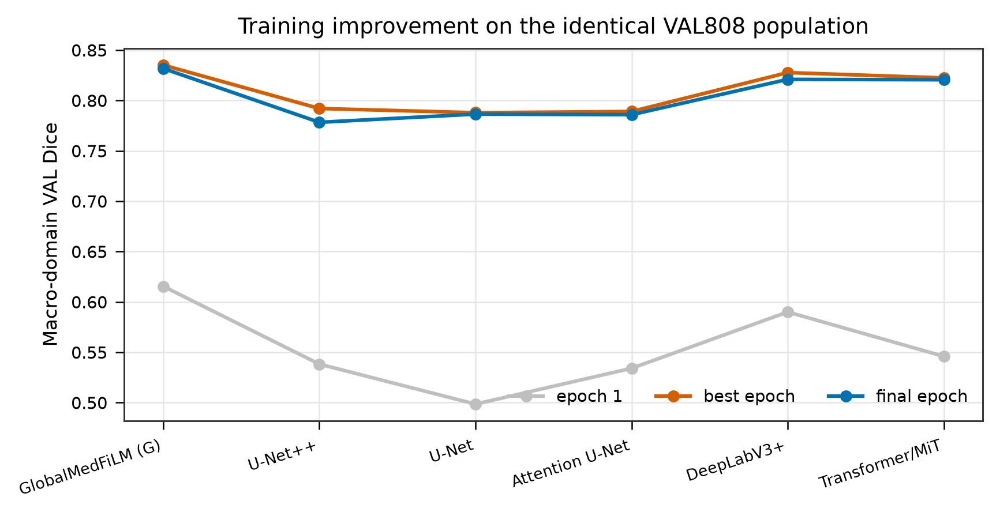

In [21]:
for name in ["T5_learning_rate_schedule", "T6_best_epoch_selection",
             "T7_multiseed_histories", "T8_training_improvement_summary"]:
    fig("Training curves", name, width=700)

In [22]:
g = hist[hist.run_id == "phase21_global_medfilm_fourdomain_seed42_clean_v3"]
piv = g.pivot_table(index="epoch", columns="metric", values="value")
print("GlobalMedFiLM: 81 epochs x", piv.shape[1], "metrics")
print("best val_macro_dice:", round(float(piv.val_macro_dice.max()), 8),
      "at epoch", int(piv.val_macro_dice.idxmax()))
print("closure best_epoch :", 66)

GlobalMedFiLM: 81 epochs x

 23 metrics
best val_macro_dice: 0.83507913 at epoch 66
closure best_epoch : 66


---

# 06 — Internal validation

Backbone versus FULL on the identical 808 samples.

In [23]:
m = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_METRICS.csv")
m[["domain", "n", "global_dice", "final_dice", "delta_dice", "final_hd95"]].to_string(index=False)

'                   domain   n  global_dice  final_dice  delta_dice  final_hd95\n                     ISIC 357     0.897189    0.898081    0.000892   25.310635\n                     BUSI  84     0.858823    0.858914    0.000091   31.717232\n                   KVASIR  87     0.820248    0.820651    0.000403   62.510323\n                      KUB 280     0.764058    0.771512    0.007454   49.604150\nMACRO_DOMAIN_EQUAL_WEIGHT 808     0.835080    0.837290    0.002210   42.285585'

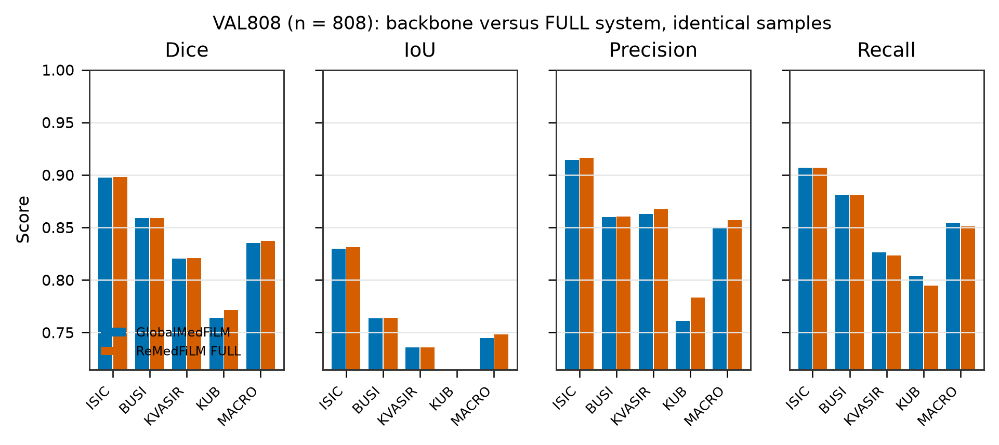

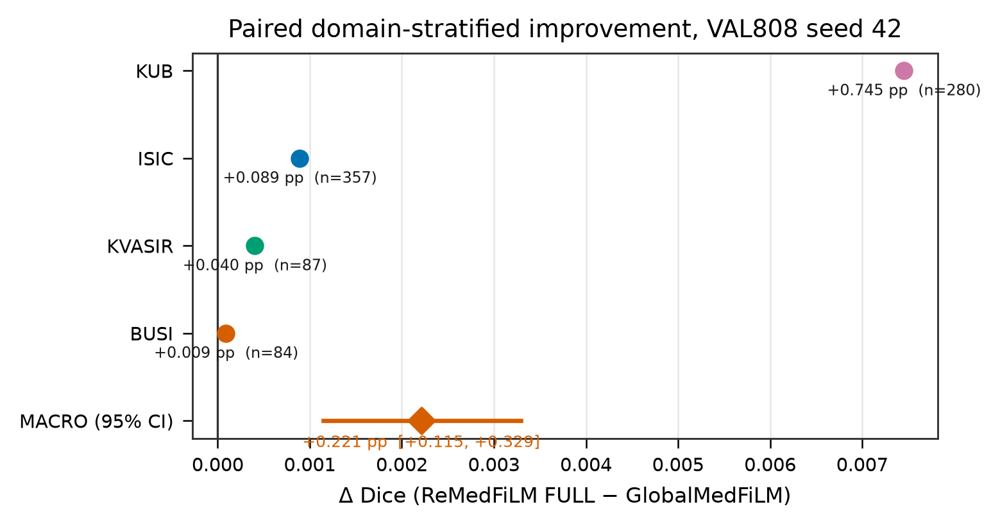

In [24]:
fig("Internal validation", "I1_domain_metric_comparison", width=800)
fig("Internal validation", "I2_paired_delta_forest", width=680)

In [25]:
paired = json.loads((TABLES / "REMEDFILM_PAIRED_DELTA.json").read_text(encoding="utf-8"))
print("paired macro Δ Dice:", f"{paired['point']:+.8f}",
      f"[{paired['ci_low']:+.8f}, {paired['ci_high']:+.8f}]")
print("B =", paired["n_boot"], "| frozen Phase 27 agreement:",
      f"{abs(paired['point'] - paired['cross_check_phase27_macro_point']):.2e}")

paired macro Δ Dice: +0.00220997 [+0.00114769, +0.00329205]
B = 10000 | frozen Phase 27 agreement: 1.77e-07


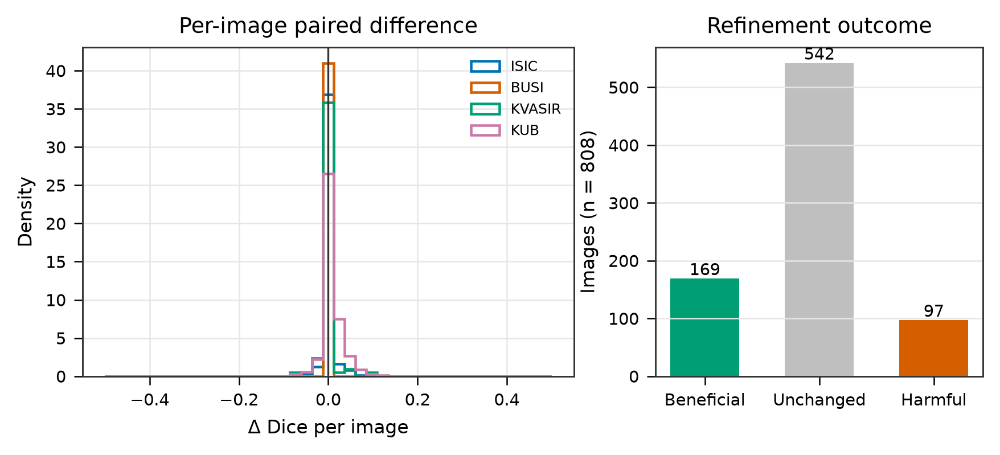

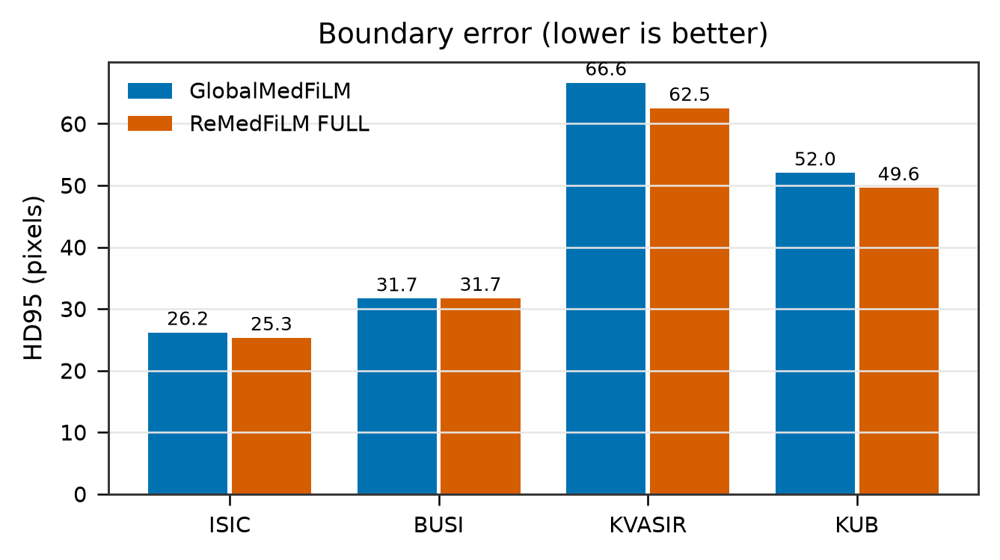

In [26]:
fig("Internal validation", "I3_paired_delta_distribution", width=760)
fig("Internal validation", "I4_hd95_comparison", width=580)

---

# 07 — Segmentation galleries

Deterministic selection: worst / median / best per domain.

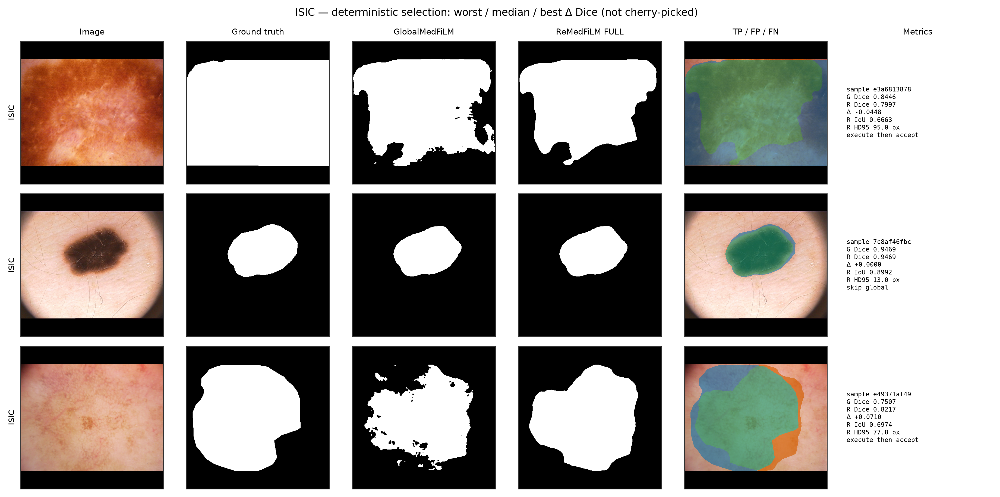

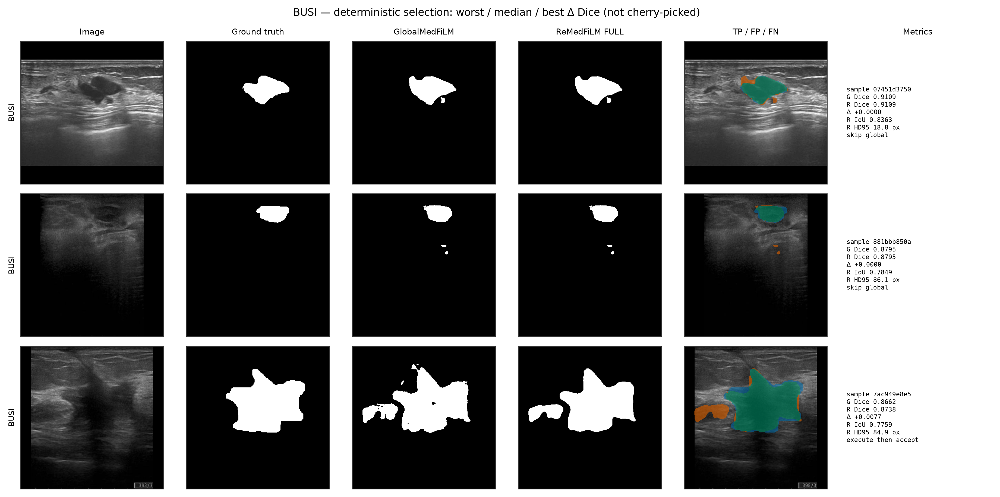

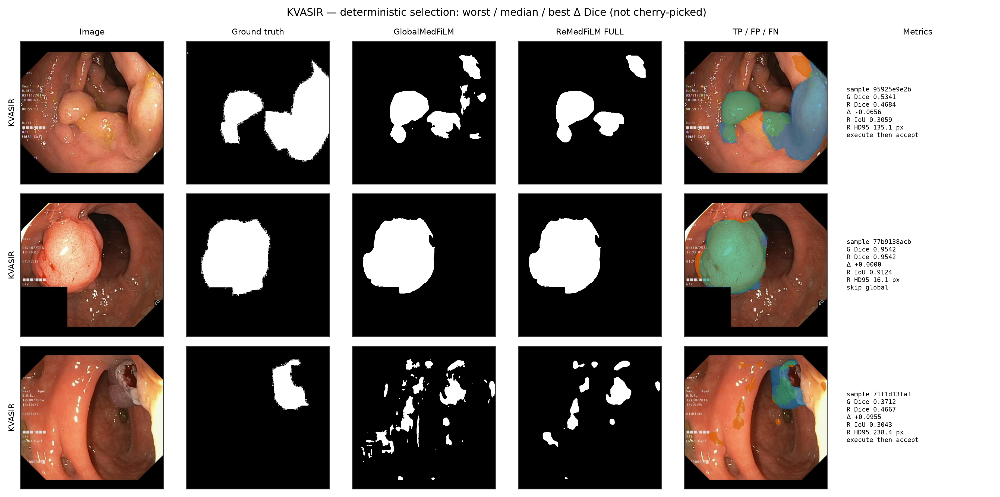

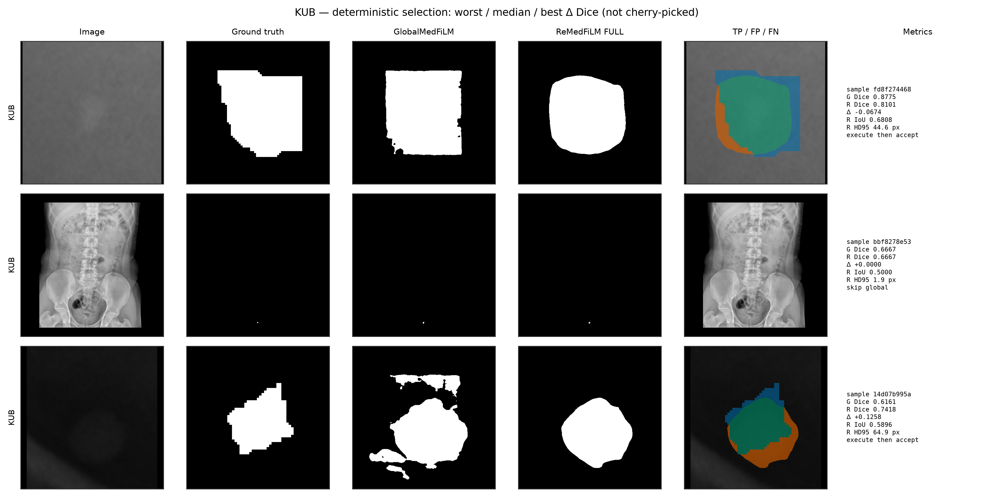

In [27]:
for dom in ["ISIC", "BUSI", "KVASIR", "KUB"]:
    fig("Semantic segmentation", f"SEG_{dom}_global_vs_full", width=900)

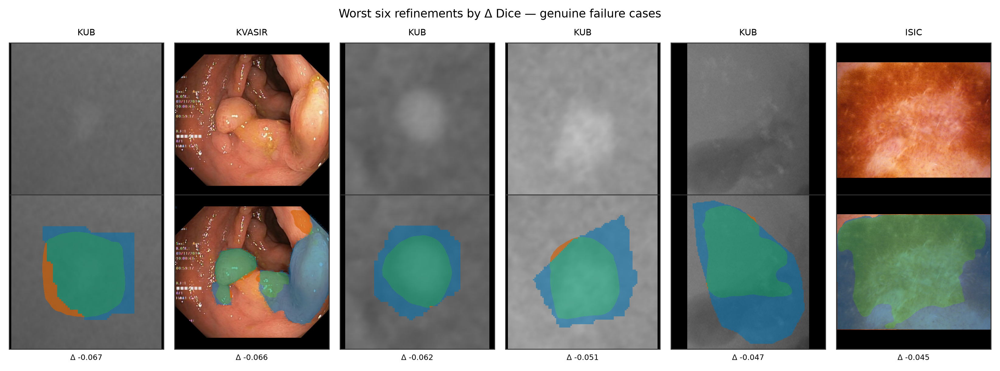

In [28]:
fig("Semantic segmentation", "SEG_failure_cases", width=920)

In [29]:
ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
print("worst six refinements (accepted, therefore residual failures):")
print(ps.nsmallest(6, "delta_dice")[["sample_id", "domain", "global_dice",
                                     "final_dice", "delta_dice"]].to_string(index=False))

worst six refinements (accepted, therefore residual failures):
                       sample_id domain  global_dice  final_dice  delta_dice
fd8f2744680aa3a805f47a8151ef9761    KUB     0.877465    0.810078   -0.067387
95925e9e2b42fd03f8ad7c6581ae5cd1 KVASIR     0.534087    0.468447   -0.065640
59fa90de5303dd9b221630fed9322bc1    KUB     0.794817    0.732750   -0.062067
142bca47012895bafb72eaea84a586cb    KUB     0.799548    0.748839   -0.050709
fc65eaa53e1756122974223b22e35f07    KUB     0.743722    0.696281   -0.047441
e3a6813878b2407c0c8c2e534de8d40a   ISIC     0.844561    0.799714   -0.044847


---

# 08 — Class and subclass analysis

Verified subgroups only — KUB stone location and size taxonomy.

In [30]:
sub = pd.read_csv(REPO / "reports/tables/phase21_kub_subgroup_analysis.csv")
sub[["subgroup", "n", "dice", "iou", "precision", "recall", "hd95"]].to_string(index=False)

'      subgroup   n     dice      iou  precision   recall      hd95\n       KUB_ALL 280 0.764058 0.650358   0.760812 0.803676 51.880826\n Bladder_Stone 144 0.733945 0.616313   0.712706 0.793832 51.864262\n  Kidney_Stone 112 0.796378 0.686368   0.823852 0.805037 51.859788\nUreteric_Stone  24 0.793914 0.686586   0.755258 0.856392 52.078386'

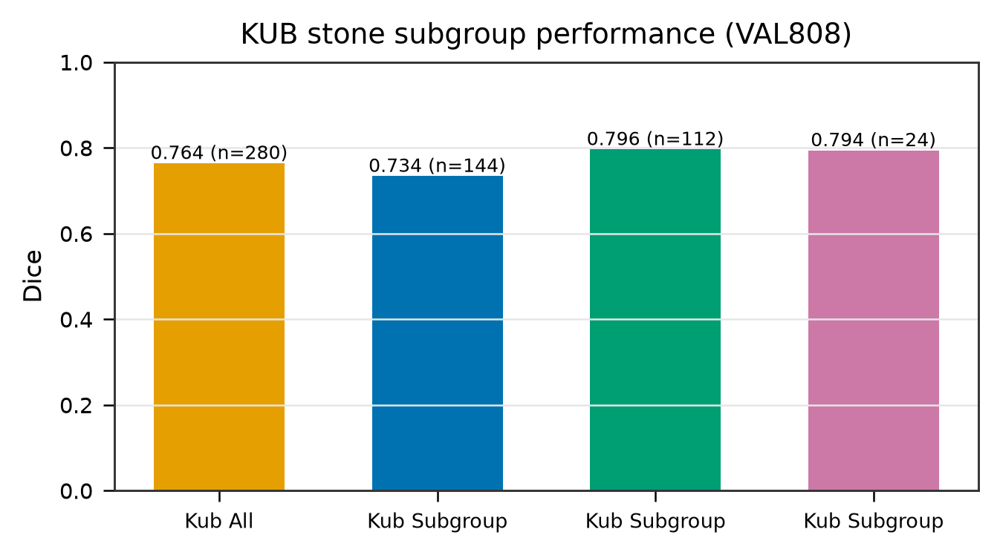

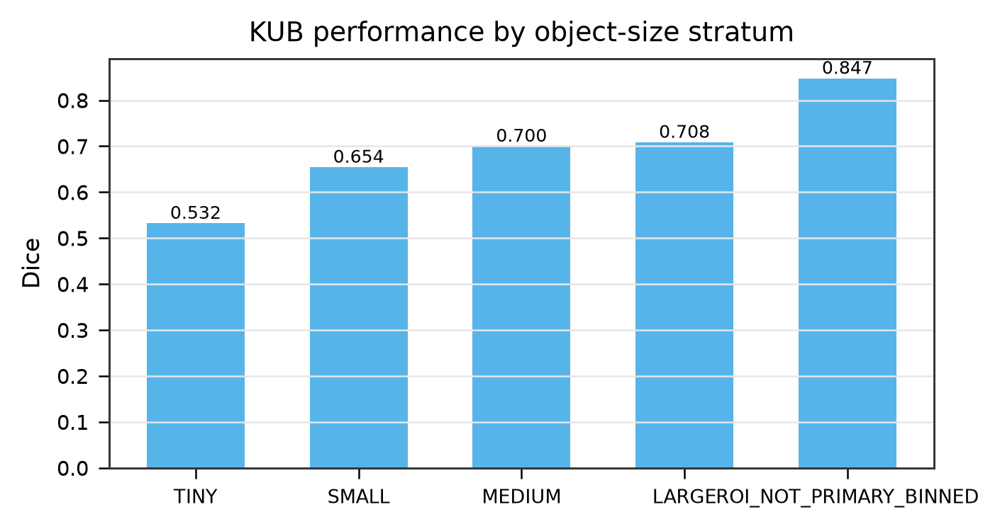

In [31]:
fig("Internal validation", "SG1_kub_stone_subgroups", width=580)
fig("Internal validation", "SG2_kub_size_stratification", width=580)

In [32]:
print("NOT_RECORDED: BUSI lesion subgroups, polyp size categories.")
print("Only KUB has a verified subgroup taxonomy in the frozen artifacts.")

NOT_RECORDED: BUSI lesion subgroups, polyp size categories.
Only KUB has a verified subgroup taxonomy in the frozen artifacts.


---

# 09 — External evaluation

884 retrospective cases, three cohorts, never pooled.

In [33]:
ext = pd.read_csv(TABLES / "REMEDFILM_EXTERNAL_METRICS.csv")
ext[ext.metric == "Dice"][["cohort", "arm", "n_total", "mean", "ci_low", "ci_high"]].to_string(index=False)

'              cohort            arm  n_total     mean   ci_low  ci_high\n        CVC-ClinicDB  GlobalMedFiLM      612 0.686568 0.626485 0.743686\n        CVC-ClinicDB ReMedFiLM_FULL      612 0.689747 0.629797 0.746428\n  BrEaST-Lesions-USG  GlobalMedFiLM      252 0.707822 0.676828 0.737830\n  BrEaST-Lesions-USG ReMedFiLM_FULL      252 0.708098 0.677001 0.738037\nStones_where_are_you  GlobalMedFiLM       20 0.080840 0.003360 0.189947\nStones_where_are_you ReMedFiLM_FULL       20 0.082126 0.004646 0.191239'

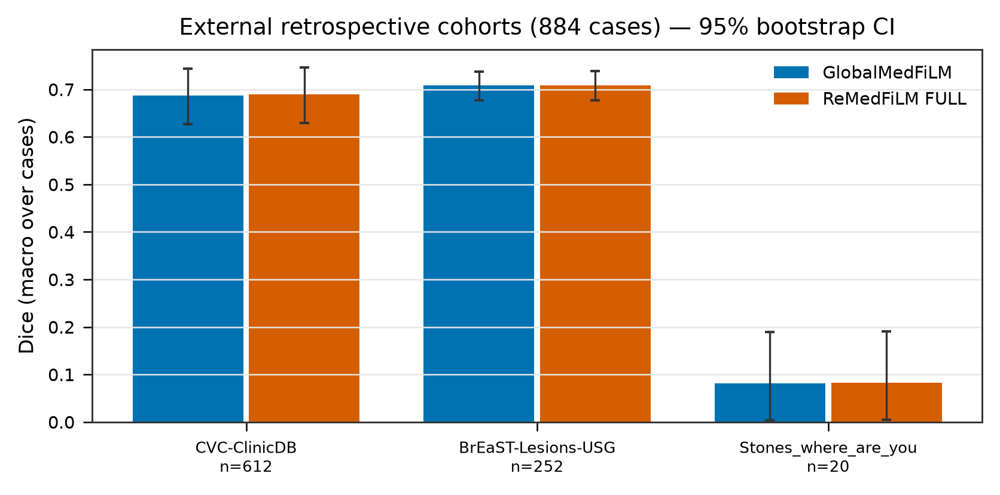

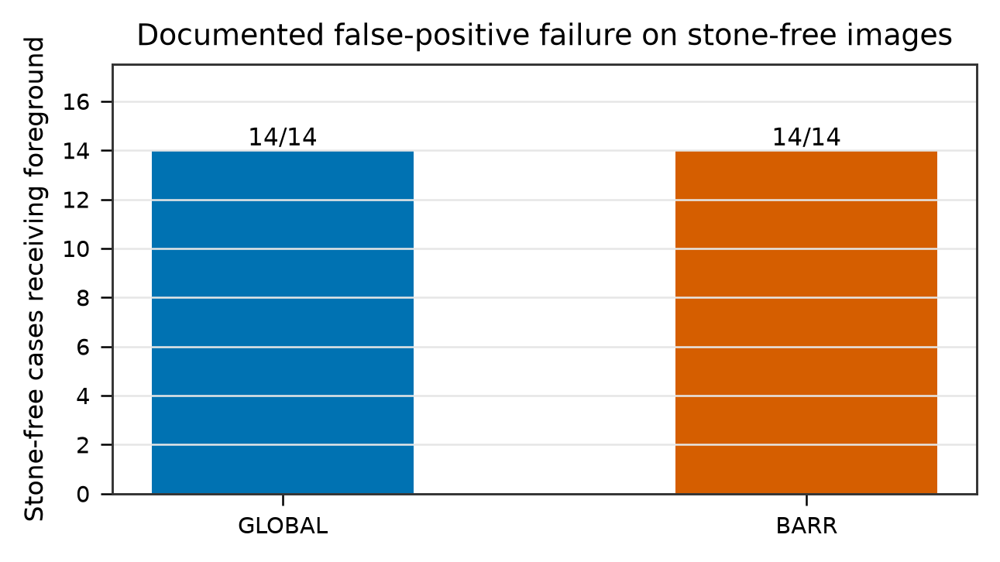

In [34]:
fig("External evaluation", "EXT01_external_dice", width=740)
fig("External evaluation", "EXT03_stonefree_false_positive", width=560)

In [35]:
pc = pd.read_csv(REPO / "reports/tables/c1_external_stress_per_case.csv")
sf = pc[pc.gt_empty.astype(str).str.lower() == "true"]
print("stone-free cases:", len(sf))
for arm, g in sf.groupby("arm"):
    print(f"  {arm:8s}: {(g.pred_empty.astype(str).str.lower() == 'false').sum()}/{len(g)} receive foreground")
print()
print("Preserved negative finding: the gate does not fix false positives on")
print("negative studies, because it scores refinement benefit, not lesion presence.")

stone-free cases: 28
  barr    : 14/14 receive foreground
  global  : 14/14 receive foreground

Preserved negative finding: the gate does not fix false positives on
negative studies, because it scores refinement benefit, not lesion presence.


---

# 10 — Component progression

Stage-wise compute and harm — across two different populations.

In [36]:
prog = pd.read_csv(TABLES / "REMEDFILM_PROGRESSION_RESULTS.csv")
prog[["stage", "stage_name", "population", "mean_dice", "net_delta_pp",
      "harm_rate", "gmacs_lower_bound"]].to_string(index=False)

'     stage                        stage_name              population  mean_dice  net_delta_pp  harm_rate  gmacs_lower_bound\n   Stage 0        GlobalMedFiLM backbone (G)                  VAL808    0.83508      0.000000   0.000000          31.551741\n   Stage 1 Unrouted regional refinement (A1) ROUTER_DEVELOPMENT_4957        NaN      0.165808   0.426669          34.782441\n   Stage 2      Learned benefit routing (A7) ROUTER_DEVELOPMENT_4957        NaN      0.724663   0.332526          32.437902\n   Stage 3        Post-safety gate (A8 FULL) ROUTER_DEVELOPMENT_4957        NaN      0.751575   0.323651          32.437902\n   Stage 4  FULL assembly on held-out VAL808                  VAL808    0.83729      0.220997   0.120050          32.437902\nAudit gate   Incremental dataset progression                     NaN        NaN           NaN        NaN                NaN'

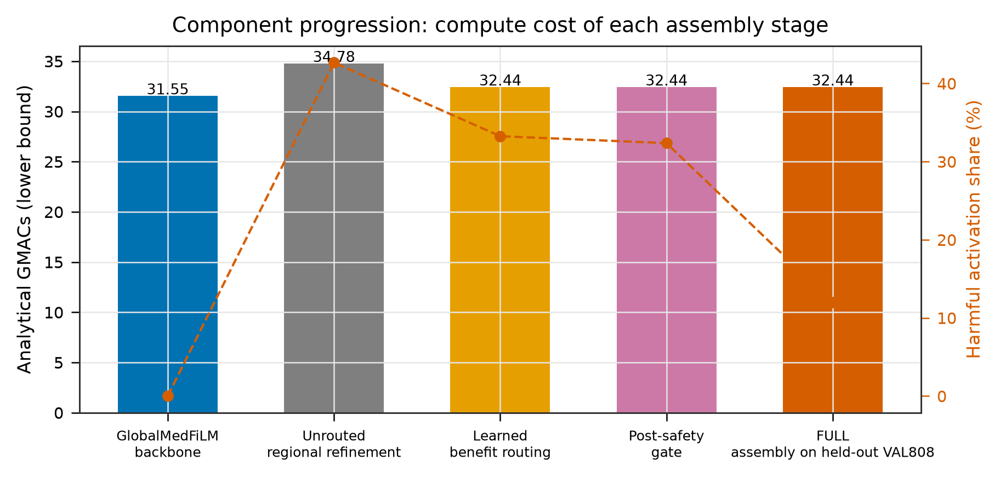

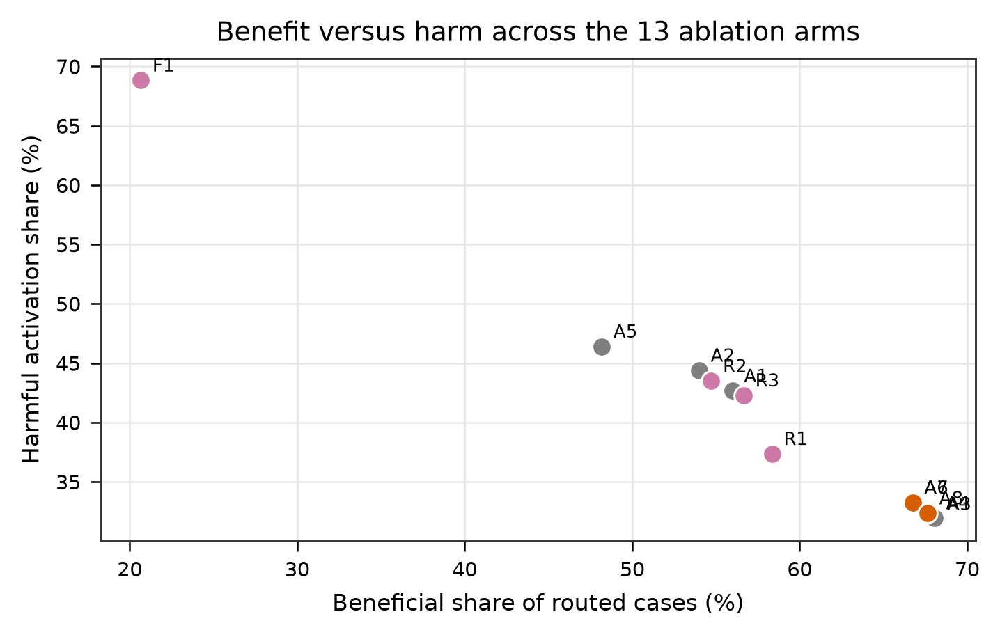

In [37]:
fig("Progression", "PROG01_stage_compute_and_harm", width=740)
fig("Progression", "PROG02_benefit_harm_tradeoff", width=620)

---

# 11 — Full ablation

13 arms on ROUTER_DEVELOPMENT, with the negative A8-vs-A7 contrast preserved.

In [38]:
abl = pd.read_csv(TABLES / "REMEDFILM_ABLATION_RESULTS.csv")
abl[["arm", "n_routed", "mean_true_delta_dice_routed", "harmful_activation_share",
     "benefit_capture_vs_positive_mass", "evidence_class"]].to_string(index=False)

'arm  n_routed  mean_true_delta_dice_routed  harmful_activation_share  benefit_capture_vs_positive_mass                   evidence_class\n A0         0                     0.000000                  0.000000                          0.000000         ENDPOINT_BY_CONSTRUCTION\n A1      4957                     0.001658                  0.426669                          1.000000         ENDPOINT_BY_CONSTRUCTION\n A2      1239                     0.001413                  0.443906                          0.245520   PRIOR_CANONICAL_EVIDENCE_EXACT\n A3      1239                     0.007185                  0.318805                          0.584331   PRIOR_CANONICAL_EVIDENCE_EXACT\n A4      1239                     0.007119                  0.319613                          0.582158   PRIOR_CANONICAL_EVIDENCE_EXACT\n A5      1239                    -0.000433                  0.464084                          0.184251   PRIOR_CANONICAL_EVIDENCE_EXACT\n A6      1239                     0.0072

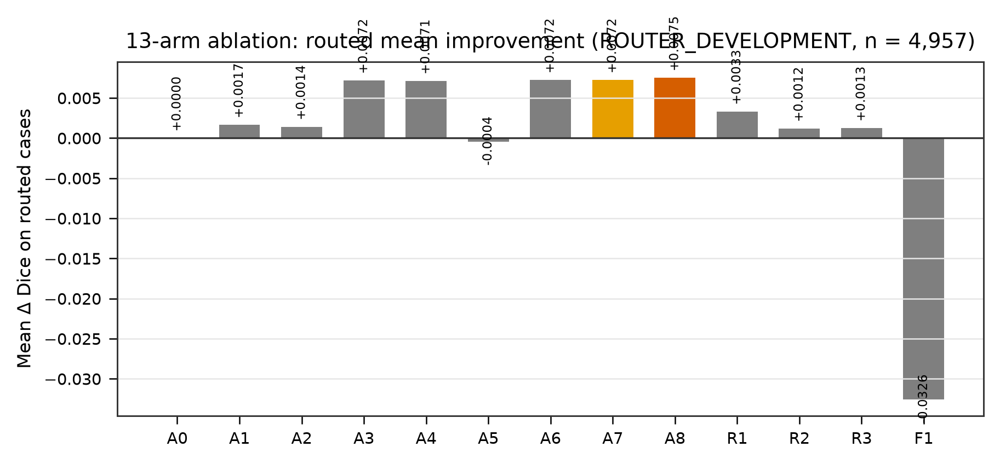

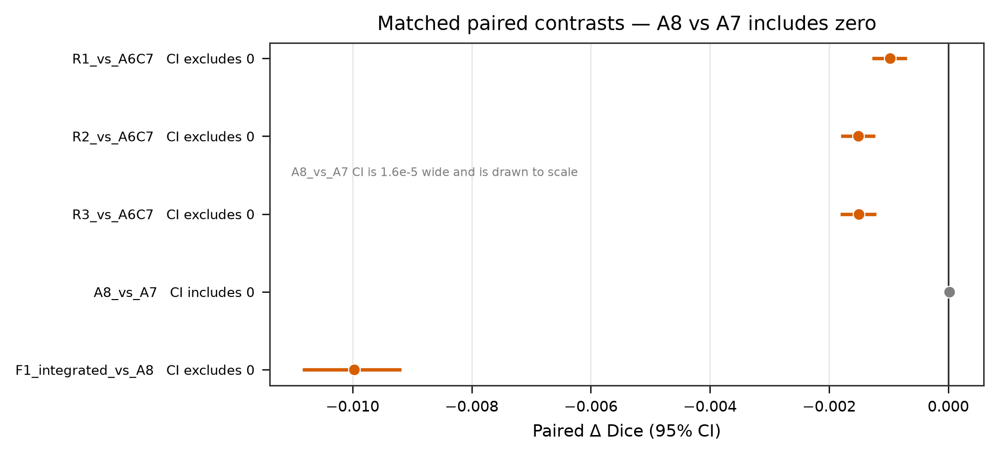

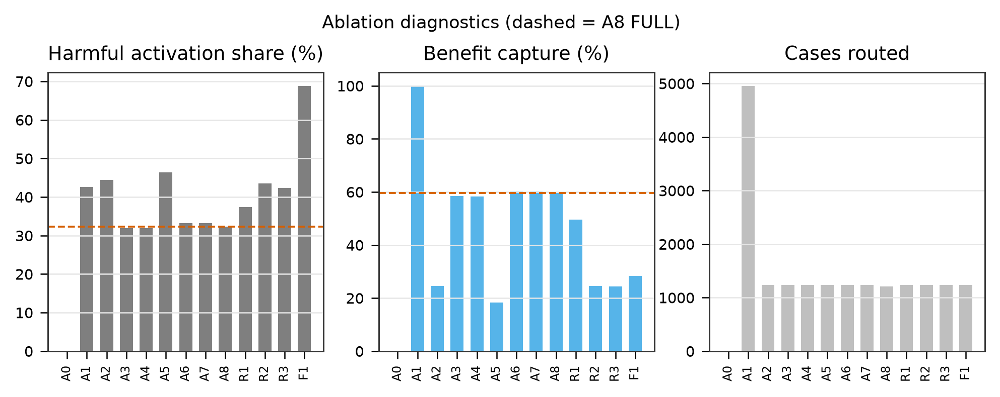

In [39]:
fig("Ablation", "ABL01_arm_mean_delta", width=780)
fig("Ablation", "ABL02_paired_contrasts_forest", width=660)
fig("Ablation", "ABL03_ablation_diagnostics", width=880)

In [40]:
bs = pd.read_csv(REPO / "reports/tables/phase28_table_08_bootstrap_statistics.csv")
a8 = bs[bs.contrast == "A8_vs_A7"].iloc[0]
print("A8 vs A7:", f"{a8.mean_difference:+.3e}",
      f"[{a8.ci95_low:+.3e}, {a8.ci95_high:+.3e}]",
      "-> includes zero:", not (a8.ci95_low > 0 or a8.ci95_high < 0))
print()
print("The pre-specified matched contrast is inconclusive. The safety gate's")
print("marginal contribution is NOT statistically established.")

A8 vs A7: +1.572e-05 [-1.431e-05, +5.101e-05] -> includes zero: True

The pre-specified matched contrast is inconclusive. The safety gate's
marginal contribution is NOT statistically established.


---

# 12 — Error propagation

Grounded stage counts and the prevented-versus-residual harm split.

In [41]:
ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
n = len(ps)
sel = int((ps.router_decision == "EXECUTE").sum())
acc = int((ps.branch == "EXECUTE_THEN_ACCEPT").sum())
rej = int((ps.branch == "EXECUTE_THEN_REJECT").sum())
print(f"images            : {n}")
print(f"router selected   : {sel} ({sel/n:.1%})")
print(f"router skipped    : {n - sel}")
print(f"safety accepted   : {acc}")
print(f"safety rejected   : {rej}")

images            : 808
router selected   : 279 (34.5%)
router skipped    : 529
safety accepted   : 266
safety rejected   : 13


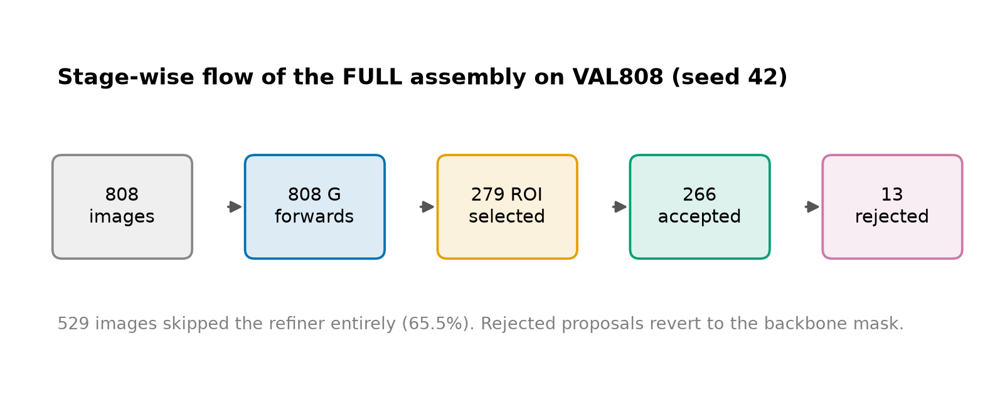

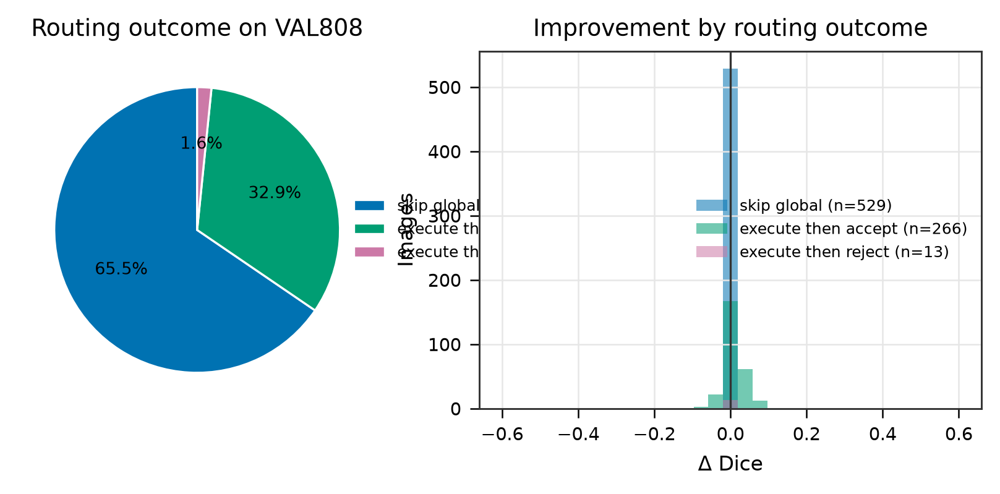

In [42]:
fig("Routing and safety", "RT02_stage_flow", width=740)
fig("Routing and safety", "RT01_routing_outcomes", width=760)

In [43]:
ex = ps[ps.router_decision == "EXECUTE"]
accd = ex[ex.branch == "EXECUTE_THEN_ACCEPT"].delta_dice
rejd = ex[ex.branch == "EXECUTE_THEN_REJECT"].delta_dice
print(f"accepted n={len(accd)}  mean Δ {accd.mean():+.6f}  harmful {int((accd < -1e-12).sum())}")
print(f"rejected n={len(rejd)}  mean Δ {rejd.mean():+.6f}  harmful {int((rejd < -1e-12).sum())}")
print()
print(f"harm prevented: {-rejd[rejd < 0].sum():.4f}")
print(f"harm delivered: {-accd[accd < 0].sum():.4f}")

accepted n=266  mean Δ +0.009204  harmful 97
rejected n=13  mean Δ +0.000000  harmful 0

harm prevented: -0.0000
harm delivered: 1.4703


---

# 13 — Statistical reproducibility

Three downstream seeds on a shared frozen backbone.

In [44]:
d = json.loads((REPO / "reports/audits/phase29_phase_d_three_seed_descriptive_summary.json").read_text(encoding="utf-8"))
pd.DataFrame([{"metric": m["metric"], "seed42": m["seed42"], "seed123": m["seed123"],
               "seed3407": m["seed3407"], "mean": m["mean"], "sd": m["sample_sd_ddof1"]}
              for m in d["per_metric"]]).round(8)

,metric,seed42,seed123,seed3407,mean,sd
0,macro_final_dice,0.837289,0.838467,0.837948,0.837901,0.000590
1,macro_global_dice,0.835079,0.835079,0.835079,0.835079,0.000000
2,macro_delta_dice,0.002210,0.003388,0.002869,0.002822,0.000590
3,n_selected,279.000000,255.000000,262.000000,265.333333,12.342339
4,selected_fraction,0.345297,0.315594,0.324257,0.328383,0.015275
5,n_accepted,266.000000,230.000000,256.000000,250.666667,18.583146
6,safety_accept_fraction,0.953405,0.901961,0.977099,0.944155,0.038414
7,n_final_refined,266.000000,230.000000,256.000000,250.666667,18.583146


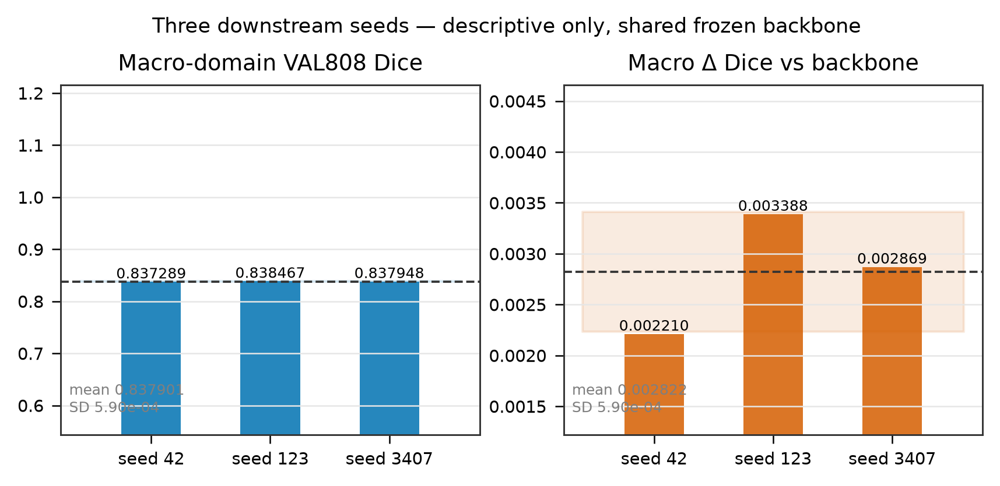

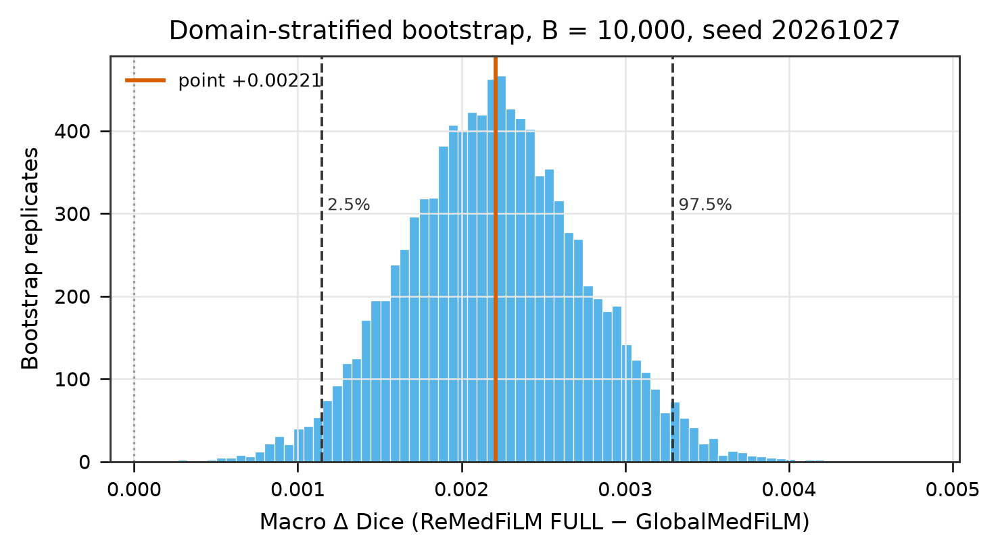

In [45]:
fig("Statistics", "STAT01_seedwise_macro_metrics", width=760)
fig("Statistics", "STAT02_bootstrap_distribution", width=620)

In [46]:
g = [m for m in d["per_metric"] if m["metric"] == "macro_global_dice"][0]
print("macro_global_dice SD across seeds:", g["sample_sd_ddof1"])
print("-> backbone identical; only downstream components were re-fitted")
print("-> NOT three independent end-to-end runs")
print("-> no p-values computed, none valid")

macro_global_dice SD across seeds: 1.3597399555105182e-16
-> backbone identical; only downstream components were re-fitted
-> NOT three independent end-to-end runs
-> no p-values computed, none valid


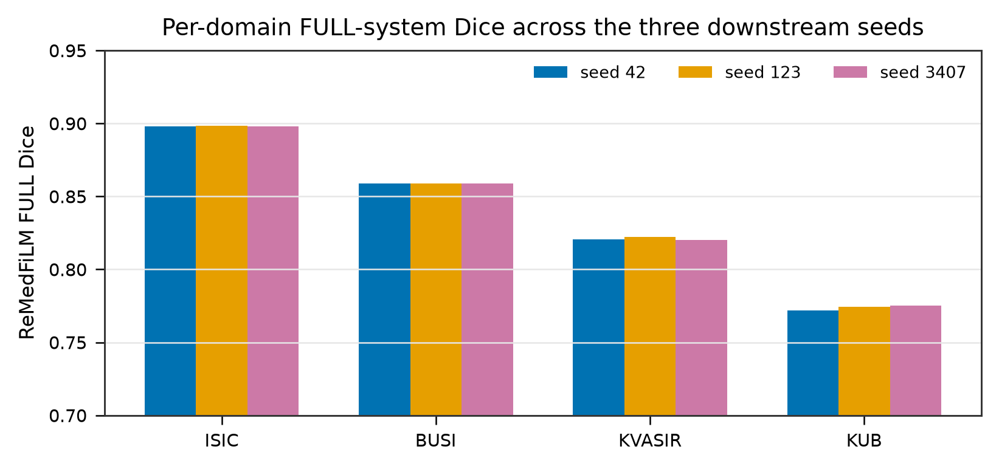

In [47]:
fig("Statistics", "STAT03_seedwise_per_domain", width=700)

---

# 14 — Robustness and interpretability

12,928 perturbation instances, zero TEST reads, zero training.

In [48]:
r = json.loads((REPO / "reports/audits/phase36_robustness_scientific_result_v1_23.json").read_text(encoding="utf-8"))
for k in ("clean_passes", "perturbed_g_forwards", "test_reads", "training", "optimizer_steps"):
    print(f"  {k:22s}: {r['counters'][k]}")
print("clean equivalence all_pass:", r["clean_equivalence"]["all_pass"])

  clean_passes          : 808
  perturbed_g_forwards  : 12928
  test_reads            : 0
  training              : 0
  optimizer_steps       : 0
clean equivalence all_pass: True


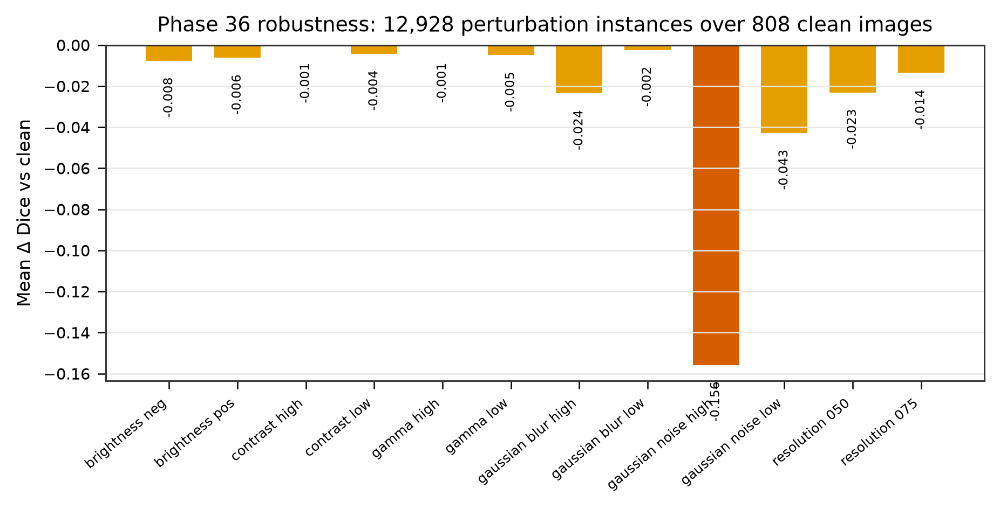

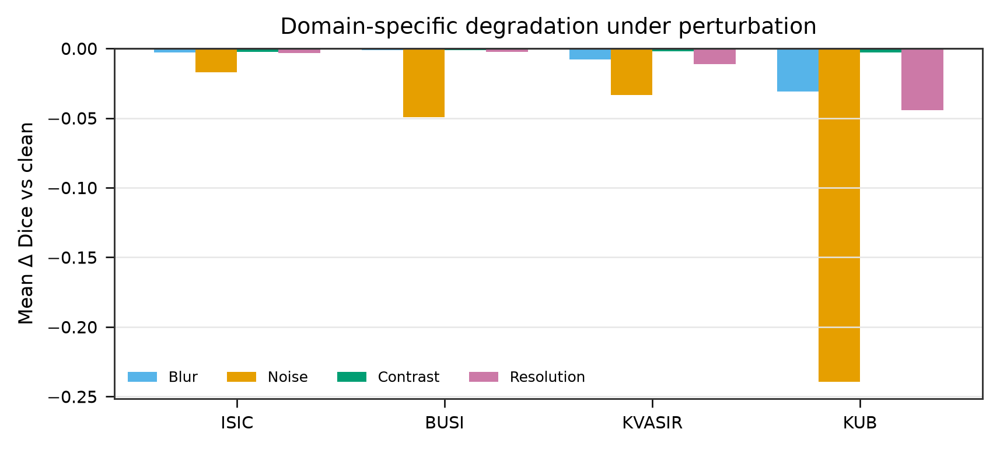

In [49]:
fig("Robustness", "ROB01_perturbation_degradation", width=800)
fig("Robustness", "ROB02_domain_degradation", width=720)

In [50]:
rows = pd.DataFrame(r["image_rows"])
kub = rows[rows.domain == "KUB"].groupby("condition").paired_delta_dice.mean().sort_values()
print("KUB worst conditions:")
print(kub.head(5).round(4).to_string())
print()
print("Interpretability: Phase 35 produced task-conditioning diagnostics, not a")
print("causal attribution study. No saliency map is offered as causal evidence.")

KUB worst conditions:
condition
GAUSSIAN_NOISE_HIGH   -0.3636
GAUSSIAN_NOISE_LOW    -0.1153
GAUSSIAN_BLUR_HIGH    -0.0563
RESOLUTION_050        -0.0544
RESOLUTION_075        -0.0342

Interpretability: Phase 35 produced task-conditioning diagnostics, not a
causal attribution study. No saliency map is offered as causal evidence.


---

# 15 — Computational efficiency

ReMedFiLM FULL plotted as its own point — the earlier report omitted it.

In [51]:
eff = pd.read_csv(TABLES / "REMEDFILM_EFFICIENCY.csv")
eff.to_string(index=False)

'                      model   params     gmacs        gmacs_semantics  latency_p50_ms              latency_p50_semantics  macro_dice population                                                                  source\n          GlobalMedFiLM (G)  3523001 31.551700 ANALYTICAL_LOWER_BOUND       15.721472 MEASURED_BATCH1_CONTROLLED_FORWARD    0.835079     VAL808 phase21_analytical_mac_count.json / phase34_efficiency_result_v1_4.json\n           ReMedFiLM (FULL)  4837420 32.437902   EXPECTED_CONDITIONAL       18.886640 MEASURED_BATCH1_CONTROLLED_FORWARD    0.837290     VAL808          phase34_parameter_count_contract.json / c2_barr_aggregate.json\n                 DeepLabV3+ 40347041       NaN           NOT_RECORDED             NaN                       NOT_RECORDED    0.827652     VAL808                         reports/tables/phase21_six_model_comparison.csv\nTransformer/MiT-style U-Net 16347777       NaN           NOT_RECORDED             NaN                       NOT_RECORDED    0.82238

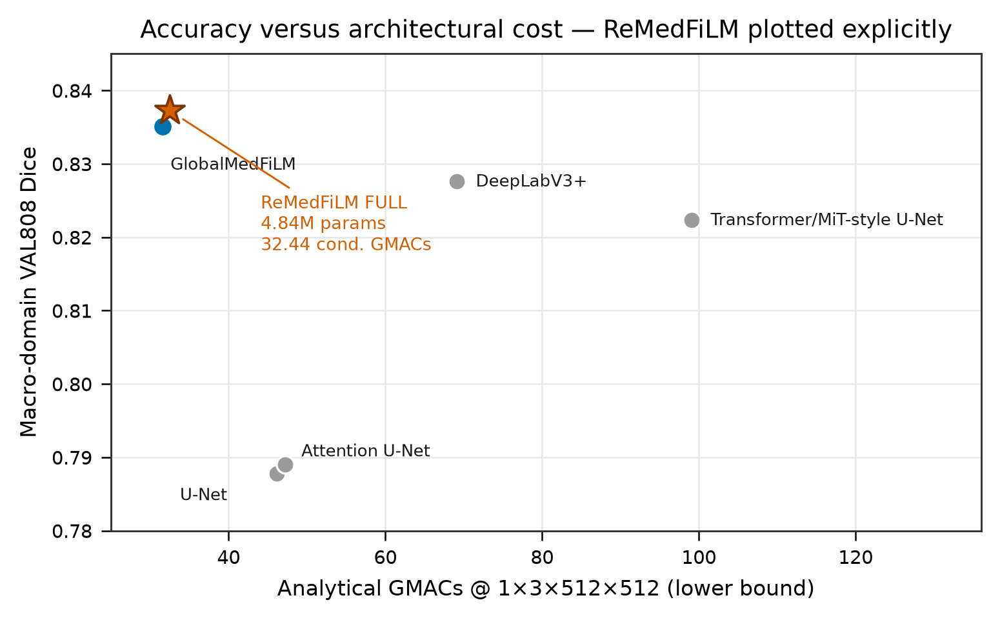

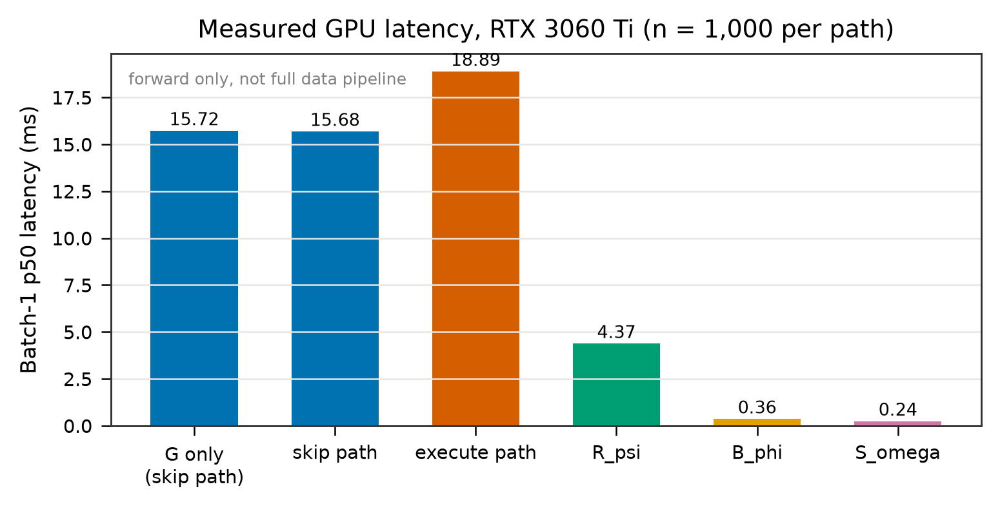

In [52]:
fig("Efficiency", "EFF01_accuracy_vs_compute", width=760)
fig("Efficiency", "EFF02_latency_breakdown", width=700)

In [53]:
c2 = json.loads((REPO / "reports/tables/c2_barr/c2_barr_aggregate.json").read_text(encoding="utf-8"))
g = c2["compute"]["analytical_gmacs_lower_bound"]
print("G only            :", g["LITERAL_GLOBAL_ONLY_C1"])
print("FULL expected     :", g["FINAL_A8_C9_EXPECTED_CONDITIONAL"])
print("always-refine     :", g["LITERAL_ALWAYS_REFINE_C2"])
print()
print("CORRECTION: earlier reports quoted 34.72 GMACs and 83.79% Dice.")
print("  34.72 is the always-refine cost, not the deployed conditional cost.")
print("  83.79% matches no frozen artifact; re-scoring gives 0.837290.")
print("  Net gain is +0.221 pp, not +0.28 pp.")

G only            : 31.551740928
FULL expected     : 32.437902022582854
always-refine     : 34.782403584

CORRECTION: earlier reports quoted 34.72 GMACs and 83.79% Dice.
  34.72 is the always-refine cost, not the deployed conditional cost.
  83.79% matches no frozen artifact; re-scoring gives 0.837290.
  Net gain is +0.221 pp, not +0.28 pp.


In [54]:
print("Four distinct 'compute' quantities — never conflate:")
print("  analytical GMACs (lower bound) | expected conditional | always-refine")
print("  measured batch-1 p50 (forward only) | full-pipeline latency NOT_RECORDED")

Four distinct 'compute' quantities — never conflate:
  analytical GMACs (lower bound) | expected conditional | always-refine
  measured batch-1 p50 (forward only) | full-pipeline latency NOT_RECORDED


---

# 16 — Historical TEST disclosure

Read from the frozen summary only. TEST is not reopened.

In [55]:
p39 = json.loads((REPO / "reports/audits/phase39_final_test_v1_2_scientific_result.json").read_text(encoding="utf-8"))
for k, v in p39.items():
    if not isinstance(v, (dict, list)):
        print(f"  {k}: {v}")

  classification: PHASE39_FINAL_TEST_SCIENTIFIC_RESULT
  evidence_class: POST_PROTOCOL_TECHNICAL_RECOVERY_TEST_RESULT_WITH_TWO_DISCLOSED_PREOUTCOME_TECHNICAL_FAILURES
  revision: ra_medfilm_barr_phase39_final_test_v1_2
  phase: 39
  method: RA-MedFiLM-BARR
  generated_utc: 2026-10-11T10:09:40Z
  population: TEST
  test_n: 1683
  phase30_qualifier: ONE_SHOT_ROUTER_HOLDOUT_RESULT_WITH_DISCLOSED_POST_FIRST_OPEN_SCIENTIFIC_SOURCE_FREEZE_DEVIATION
  source_sha256: e3544634095d86853ce0e7b2fa55bac4a0ecf84cef65ea6fab163a1466606d3c
  manifest_schema_domain_field: dataset


In [56]:
dom = p39.get("per_domain") or p39.get("domains") or []
if isinstance(dom, dict):
    dom = [{"domain": k, **v} for k, v in dom.items()]
print(pd.DataFrame(dom).to_string(index=False) if dom else "per-domain block absent")
print()
print("One-shot access consumed. No C1/C2/C3 comparison exists on TEST.")

per-domain block absent

One-shot access consumed. No C1/C2/C3 comparison exists on TEST.


---

# 17 — Conclusions and limitations

Established, descriptive, and missing — kept strictly apart.

In [57]:
summary = pd.DataFrame([
    ("GlobalMedFiLM VAL808 macro Dice 0.835079", "ESTABLISHED", "Phase 21"),
    ("ReMedFiLM FULL VAL808 macro Dice 0.837290", "ESTABLISHED", "Phase 27 re-scored"),
    ("Paired macro Δ +0.00221 [0.00115, 0.00329]", "ESTABLISHED", "10k bootstrap"),
    ("A8 vs A7 matched contrast", "INCONCLUSIVE (CI includes 0)", "Phase 28"),
    ("13-arm ablation on 4,957", "ESTABLISHED", "Phase 28"),
    ("External 884 retrospective", "ESTABLISHED (no pooling)", "C1 external"),
    ("Stone-free false positives", "NEGATIVE FINDING 14/14", "C1 external"),
    ("Robustness, 12 perturbations", "ESTABLISHED", "Phase 36"),
    ("C1 learned vs identity FiLM", "NOT_ESTABLISHED", "0/6 runs"),
    ("C2 causal component attribution", "NOT_ESTABLISHED", "not executed"),
    ("C3 8-model x 3-seed benchmark", "NOT_ESTABLISHED", "0/24 cells"),
    ("Prospective external validation", "NOT_ESTABLISHED", "no cohort"),
    ("TEST comparative endpoint", "NOT_ESTABLISHED", "access consumed"),
], columns=["claim", "status", "evidence"])
summary

,claim,status,evidence
0,GlobalMedFiLM VAL808 macro Dice 0.835079,ESTABLISHED,Phase 21
1,ReMedFiLM FULL VAL808 macro Dice 0.837290,ESTABLISHED,Phase 27 re-scored
2,"Paired macro Δ +0.00221 [0.00115, 0.00329]",ESTABLISHED,10k bootstrap
3,A8 vs A7 matched contrast,INCONCLUSIVE (CI includes 0),Phase 28
4,"13-arm ablation on 4,957",ESTABLISHED,Phase 28
5,External 884 retrospective,ESTABLISHED (no pooling),C1 external
6,Stone-free false positives,NEGATIVE FINDING 14/14,C1 external
7,"Robustness, 12 perturbations",ESTABLISHED,Phase 36
8,C1 learned vs identity FiLM,NOT_ESTABLISHED,0/6 runs
9,C2 causal component attribution,NOT_ESTABLISHED,not executed


In [58]:
print("FINAL STATEMENT")
print("---------------")
print("ReMedFiLM FULL is the proposed method throughout; GlobalMedFiLM is its")
print("backbone and an ablation comparator.")
print()
print("No model was retrained. No new inference was run. TEST was not reopened.")
print("Missing experiments are disclosed, not simulated.")

FINAL STATEMENT
---------------
ReMedFiLM FULL is the proposed method throughout; GlobalMedFiLM is its
backbone and an ablation comparator.

No model was retrained. No new inference was run. TEST was not reopened.
Missing experiments are disclosed, not simulated.


In [59]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
